# ERT data contracts and geometry

**Question:** What does the available ERT source contract permit us to compute before any field inversion?

**Level 1 — Foundations**  
**Prerequisites:** Python basics; 35 min.



## Objectives

Question: What does a flat-half-space factor recover from a synthetic Wenner line, and what evidence is missing for the linked Slagdump field case?



## Setup

Uses repository modules and committed records through a discovered root; it downloads and mutates nothing. Install exact pins: `pip install numpy==2.2.6 matplotlib==3.10.8`



## Data

Provider-linked Slagdump source is documented, but no raw ERT file is present; upstream counts are metadata only.


## Method

A four-electrode datum uses current A/B and potential M/N. `R=ΔV/I` (Ω), `ρₐ=K R` (Ω·m), with `K=2π/(1/AM−1/AN−1/BM+1/BN)` in m for surface electrodes under a homogeneous half-space convention. Check sign and file-specific array ordering. The product parser preserves electrode coordinates, A-B-M-N indices and resistance; it does not infer absent columns. The source ledger describes the Slagdump example as provider-linked, but raw `.ohm` bytes are absent here and redistribution rights are not established. Thus no field pseudosection or inversion is fabricated. The executable diagnostic reports source readiness and plots only the committed mesh controls, clearly labelled as settings rather than geophysical measurements.

The geometric factor converts resistance under a half-space assumption; it is not true resistivity at a depth. Many cells affect each datum, creating broad sensitivity and depth-dependent resolution. Log parameterization protects positivity but changes smoothness meaning. Mesh refinement must be judged by stable predictions under comparable data fit, not cell size alone.



### Experiment: geometry, sign and apparent resistivity

For a Wenner-α array with equal spacing `a`, the flat homogeneous half-space factor is `K=2πa` and `ρa=KR`. This converts measured resistance; it is not a depth-localized resistivity. Build a seeded-free synthetic fixture (no field data or rights question), parse it from bytes with the product’s strict `.ohm` parser, and vary only spacing. Then inject a negative resistance: verify that parsing preserves it and product QC reports the row instead of silently deleting it.

In [1]:
# Execute the documented experiment with the repository evidence.
import sys, numpy as np
from pathlib import Path

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
import ert

rho_true = 120.0


def wenner(spacing):
    xz = [(i * spacing, 0.0) for i in range(33)]
    resistance = rho_true / (2 * np.pi * spacing)
    rows = [f"{i + 1} {i + 4} {i + 2} {i + 3} {resistance:.12g}" for i in range(30)]
    lines = [
        "# Synthetic teaching fixture; not field data",
        "# Wenner alpha; x/z m; R Ohm",
        "33# Number of sensors",
        "#x z",
        *[f"{x} {z}" for x, z in xz],
        "30# Number of data",
        "#a b m n R",
        *rows,
    ]
    return ert.parse_ohm_bytes(("\n".join(lines) + "\n").encode())




### Recompute the flat half-space response

The synthetic Wenner fixture generator returns parsed measurements through the product parser. This step varies electrode spacing, applies product flat-halfspace factors, and verifies that apparent resistivity recovers the known homogeneous half-space value.

In [2]:
# Recompute the flat half-space response.
for a in (1.0, 2.0, 4.0):
    survey = wenner(a)
    K = float(ert.flat_halfspace_factors(survey)[0])
    rho = K * survey.resistance_ohm[0]
    assert np.isclose(rho, rho_true)
    print(f"spacing={a:g} m; K={K:.5g} m; R={survey.resistance_ohm[0]:.5g} Ohm; rho_a={rho:.2f} Ohm m")


spacing=1 m; K=6.2832 m; R=19.099 Ohm; rho_a=120.00 Ohm m
spacing=2 m; K=12.566 m; R=9.5493 Ohm; rho_a=120.00 Ohm m
spacing=4 m; K=25.133 m; R=4.7746 Ohm; rho_a=120.00 Ohm m


### Exercise strict rejection and QC behavior

This independent synthetic input includes one negative resistance. The strict parser and QC method retain the row identity and report it explicitly; no field measurements or restricted source data are loaded.

In [3]:
# Exercise strict rejection and QC behavior.
survey = wenner(2.0)
lines = [
    "# Synthetic teaching fixture; not field data",
    "# Wenner alpha; x/z m; R Ohm",
    "33# Number of sensors",
    "#x z",
    *[f"{i * 2} 0" for i in range(33)],
    "30# Number of data",
    "#a b m n R",
    *[f"{i + 1} {i + 4} {i + 2} {i + 3} {-1 if i == 2 else 1}" for i in range(30)],
]
signed = ert.parse_ohm_bytes(("\n".join(lines) + "\n").encode())
report = ert.qc(signed)
assert signed.abmn.shape == (30, 4) and report["negative_resistance_rows"] == [2]
print("Strict parser retained ABMN and negative resistance row 2; no field file was used.")


Strict parser retained ABMN and negative resistance row 2; no field file was used.


Recompute the predeclared split on the parsed synthetic acquisition.

In [4]:
# Recompute the predeclared split on the parsed synthetic acquisition.
train_rows, held_rows = ert.holdout_indices(signed)
print("training:", len(train_rows), "held out:", len(held_rows))


training: 24 held out: 6


Recompute analytical half-space factors on the same survey.

In [5]:
# Recompute analytical half-space factors on the same survey.
factor_check = ert.flat_halfspace_factors(signed)
print("factor range m:", float(factor_check.min()), float(factor_check.max()))


factor range m: 12.566370614359172 12.566370614359172


## Results

For spacings 1, 2 and 4 m, the product factors recover 120.00 Ω·m each from the constructed homogeneous half-space. The strict parser retains and flags injected negative-resistance row 2; no raw Slagdump `.ohm` file is present locally.
### Linked data and authored control

Slagdump is link-only without raw bytes; executable parser and geometric-factor claims come from the separate synthetic Wenner sample.

**Answer:** For spacings 1, 2 and 4 m, the product factors recover 120.00 Ω·m each from the constructed homogeneous half-space. The strict parser retains and flags injected negative-resistance row 2; no raw Slagdump `.ohm` file is present locally.


In [6]:
from pathlib import Path
from importlib.metadata import version

print("Runtime versions:", {name: version(name) for name in ["numpy", "matplotlib"]})
import numpy as np

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir() and (p / "data-pipeline").is_dir())
# Verify source ledger and local presence of raw ERT inputs.
import json
from pathlib import Path

ledger = json.loads((root / "data/source-ledger.json").read_text(encoding="utf-8"))
print("ledger mentions Slagdump:", "slagdump" in json.dumps(ledger).lower())
raw = list((root / "data").rglob("*.ohm"))
print("local .ohm files:", raw, "; inversion from field arrays possible:", bool(raw))


Runtime versions: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
ledger mentions Slagdump: True
local .ohm files: [] ; inversion from field arrays possible: False


### Wenner spacing under a flat half-space

The known 120 Ω·m control tests the geometric factor before topography, lateral bodies or field noise are introduced.

paraDX [0.3, 0.45] dimensionless; maximum cell size [10.0, 15.0] m; alternate/default ratios 1.5 1.5


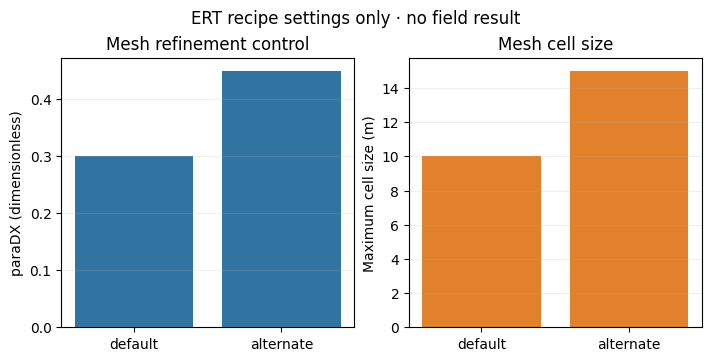

In [7]:
# Read default and alternate mesh parameters from the source AST; no mesh or field model is generated.
import numpy as np
import matplotlib.pyplot as plt
import ert

default = ert.INVERSE_OPTIONS
alternate = ert.ALTERNATE_MESH_OPTIONS
labels = ["default", "alternate"]
dx = [default["paraDX"], alternate["paraDX"]]
cell = [default["paraMaxCellSize"], alternate["paraMaxCellSize"]]
print(
    "paraDX",
    dx,
    "dimensionless; maximum cell size",
    cell,
    "m; alternate/default ratios",
    cell[1] / cell[0],
    dx[1] / dx[0],
)
fig, ax = plt.subplots(1, 2, figsize=(7, 3.5), constrained_layout=True)
x = np.arange(2)
ax[0].bar(x, dx, color="#3274a1")
ax[0].set(xticks=x, xticklabels=labels, ylabel="paraDX (dimensionless)", title="Mesh refinement control")
ax[1].bar(x, cell, color="#e1812c")
ax[1].set(xticks=x, xticklabels=labels, ylabel="Maximum cell size (m)", title="Mesh cell size")
[a.grid(axis="y", alpha=0.2) for a in ax]
fig.suptitle("ERT recipe settings only · no field result")
plt.show()


The reviewed Slagdump source is provider-link-only and the raw .ohm file is absent in this checkout. Therefore upstream counts cannot be converted into electrode positions, resistance values, reciprocity statistics or a field inversion. Do not draw a Slagdump pseudosection from invented or substituted values. The level-one experiment uses an original, explicitly synthetic Wenner sample to execute the product parser, apparent-resistivity geometry and QC flagging. The homogeneous half-space factor is a diagnostic approximation; topography and subsurface heterogeneity invalidate its interpretation as a local resistivity-at-depth. Rights status, raw-file identity, coordinate frame and data uncertainty remain part of any future field analysis.

## Summary

The analytical control verifies parser and geometric-factor behavior under a homogeneous half-space. It cannot validate Slagdump field data: without raw electrode and resistance records, no field pseudosection, reciprocity check or inversion is justified.



## References

- [https://www.pygimli.org/user-guide/inversion/](https://www.pygimli.org/user-guide/inversion/)
- [https://www.pygimli.org/_examples_auto/3_ert/plot_02_ert_field_data/](https://www.pygimli.org/_examples_auto/3_ert/plot_02_ert_field_data/)